<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🧠 Supervisor：把「派单」做成工具调用，用 `asyncio.gather` 并行，子 agent 只回传压缩结果

**一句话定位**：多子主题任务让单 agent 的 context 互相打架；supervisor 把每个子主题派给一个**拥有干净 context 的子 agent**，只收回压缩结果。派单本身就是一次 tool call，所以「要不要并行」是模型在 prompt 约束下自己决定的，可以被评估。
> 对应主课 `4_a_🔥_research_supervisor.ipynb`；langchain-core 1.4 核对 `@tool` 装饰 Pydantic class 仍得到 `StructuredTool`。

</div>

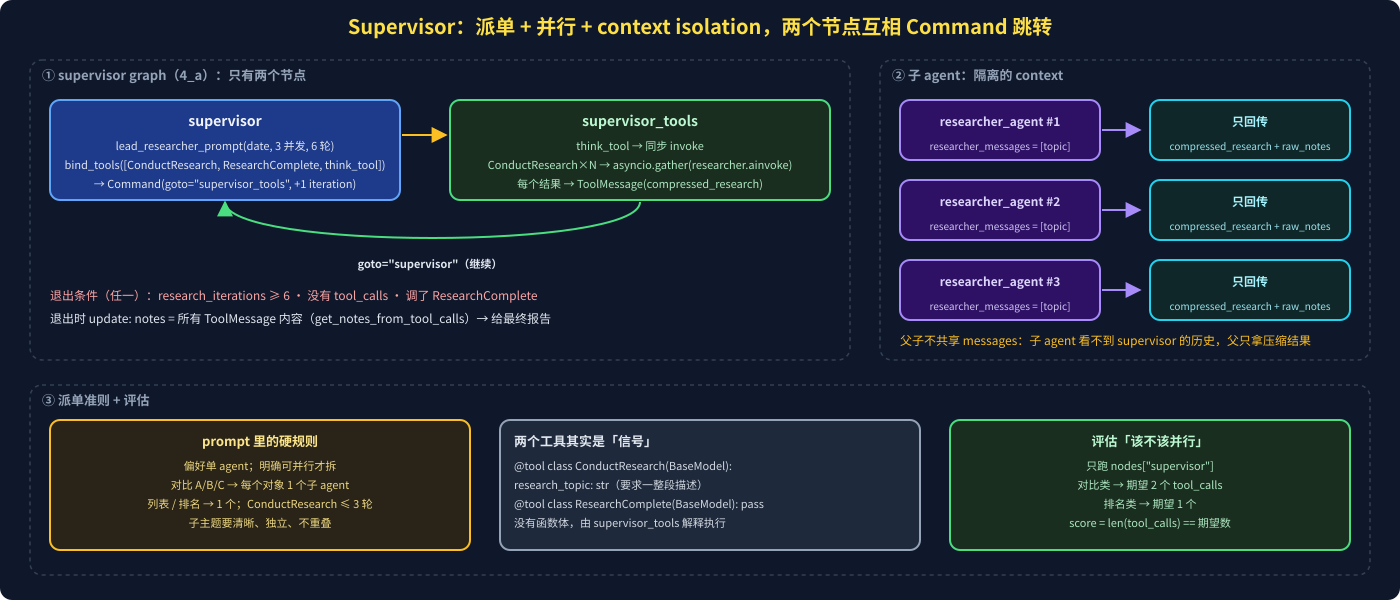

In [ ]:
from IPython.display import SVG
SVG(filename="assets/04_supervisor.svg")

### 1️⃣ 两个「假工具」+ 一个 think_tool

In [ ]:
from langchain_core.tools import tool
from pydantic import BaseModel, Field

@tool
class ConductResearch(BaseModel):
    """Tool for delegating a research task to a specialized sub-agent."""
    research_topic: str = Field(description="The topic to research. Should be a single topic, and should be described in high detail (at least a paragraph).")

@tool
class ResearchComplete(BaseModel):
    """Tool for indicating that the research process is complete."""

supervisor_tools = [ConductResearch, ResearchComplete, think_tool]

`@tool` 装饰 Pydantic class：schema 来自字段，描述来自 docstring，**没有函数体** —— 模型「调用」它只是发出结构化意图，真正的动作由 `supervisor_tools` 节点解释：`ConductResearch` → 起子 agent；`ResearchComplete` → 结束；`think_tool` → 原样记录。

### 2️⃣ `supervisor_tools` 的骨架

In [ ]:
async def supervisor_tools(state) -> Command[Literal["supervisor", "__end__"]]:
    msgs = state["supervisor_messages"]; last = msgs[-1]
    if state.get("research_iterations", 0) >= max_researcher_iterations or not last.tool_calls \
       or any(c["name"] == "ResearchComplete" for c in last.tool_calls):
        return Command(goto=END, update={"notes": get_notes_from_tool_calls(msgs), "research_brief": state.get("research_brief", "")})

    tool_messages = []
    for c in (c for c in last.tool_calls if c["name"] == "think_tool"):
        tool_messages.append(ToolMessage(content=think_tool.invoke(c["args"]), name=c["name"], tool_call_id=c["id"]))

    research_calls = [c for c in last.tool_calls if c["name"] == "ConductResearch"]
    results = await asyncio.gather(*[                                   # 🔑 并行：一轮里 N 个 ConductResearch 同时跑
        researcher_agent.ainvoke({"researcher_messages": [HumanMessage(content=c["args"]["research_topic"])],
                                  "research_topic": c["args"]["research_topic"]})
        for c in research_calls])
    tool_messages += [ToolMessage(content=r.get("compressed_research", "Error synthesizing research report"),
                                  name=c["name"], tool_call_id=c["id"]) for r, c in zip(results, research_calls)]
    raw = ["\n".join(r.get("raw_notes", [])) for r in results]
    return Command(goto="supervisor", update={"supervisor_messages": tool_messages, "raw_notes": raw})

| 设计点 | 为什么 |
|---|---|
| 子 agent 用**自己的 state key**（`researcher_messages`）启动 | 父图的 `supervisor_messages` 不会流进去 → context isolation |
| 子 agent 的 `output_schema` 只有 `compressed_research` / `raw_notes` | 父图只拿到压缩结果，长轨迹留在子图 |
| 结果写成 `ToolMessage` | 和 tool call id 配对，模型下一轮能读；退出时 `get_notes_from_tool_calls` 把所有 ToolMessage 内容收成 `notes` |
| `research_iterations` 计 **supervisor 节点次数**（含 think_tool 轮） | 所以 prompt 里说「ConductResearch ≤ 3 次」，代码上限是 6 |
| 异常 → `goto=END` | 任何一个子 agent 抛错都结束整轮，宁可少研究不要卡死 |

### 3️⃣ 评估：只跑 `supervisor` 节点

`supervisor_agent.nodes["supervisor"].ainvoke(inputs)` 返回 `Command`，所以 evaluator 读 `outputs["output"].update["supervisor_messages"][-1].tool_calls`；「对比 OpenAI vs Gemini」期望 2 个 tool_calls，「Chelsea 前三中餐」期望 1 个。用 `aevaluate` 因为节点是 async。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**🆕 2026-10 对照**

| 本课 | deepagents 0.7（官方 deep research 例子） |
|---|---|
| `ConductResearch` 假工具 | 内置 `task(description, subagent_type)` |
| `ResearchComplete` | 不需要：不发 tool_calls 即结束 |
| `asyncio.gather` | 一轮多个 `task` 调用由 ToolNode 并发执行 |
| 子 agent 回传 `compressed_research` | 子代理只把最终消息回传父代理 |
| `max_concurrent_researchers=3` / 轮数限制写进 prompt | 同样写进 prompt（3 并发 / 3 轮），`think_tool` 保留 |

引用的 Open Deep Research 仓库 2026-08-21 已归档；但「单 agent 处理多子主题会 context clash、supervisor 要按需决定是否并行」这两个结论没过时。

</div>

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 把连贯主题硬拆给多个子 agent | 重复搜索 + 结论冲突；prompt 明确「偏好单 agent」 |
| 子 agent 的 state 用了父图同名 key `messages` | 父子消息串线，隔离失效 |
| 忘了把 `ToolMessage.tool_call_id` 对上 | 模型下一轮看到孤儿 tool call，Anthropic API 直接 400 |
| 在 notebook 里 `asyncio.gather` 报「event loop already running」 | 课程用 `nest_asyncio.apply()` 兜底；顶层用 `await` 就不需要 |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：supervisor = **`supervisor`（决定派不派）⇄ `supervisor_tools`（真的派、并行等结果）** 两个节点互相 `Command` 跳；派单是一次 `ConductResearch` tool call，子 agent 用自己的 state 起、只回传压缩结果；**能单线就别派**，派不派的判断用 eval 量。

</div>